# 13. The quantum price

How long would a fault-tolerant quantum computer take to find the ground-state energy of the
J1-J2 model to precision $\epsilon$? The answer comes in three factors:

$$
\text{time} \;=\; \underbrace{\frac{\pi\lambda}{2\epsilon}}_{\text{walk calls}} \times
\underbrace{\text{Toffolis per call}}_{\sim\,\text{number of terms}} \times
\underbrace{t_\text{Toffoli}}_{\text{hardware}} \;\times\; \frac{1}{\gamma^2}.
$$

This notebook builds the first three. The last one, the overlap $\gamma$ of the starting state with the
ground state, is notebook 14.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane.estimator as qre

from dmrg_from_scratch import j1j2_cylinder
from dmrg_from_scratch.resources import SECONDS_PER_TOFFOLI, qpe_cost, walk_operator

## 1. Block encoding: the one-norm $\lambda$ is the price tag

Write $H = \sum_k c_k P_k$ as a sum of Pauli strings. Qubitization [Low and Chuang,
[arXiv:1610.06546](https://arxiv.org/abs/1610.06546)] builds a unitary walk operator whose eigenphases are
$\theta = \arccos(E/\lambda)$, with $\lambda = \sum_k |c_k|$. Phase estimation reads $\theta$, so to know $E$ to
$\epsilon$ it must know $\theta$ to about $\epsilon/\lambda$, which takes about $\pi\lambda/(2\epsilon)$ calls of the walk
operator [Babbush et al., [arXiv:1805.03662](https://arxiv.org/abs/1805.03662)].

For the Heisenberg model each bond $\mathbf S_i\cdot\mathbf S_j = \tfrac14(X_iX_j + Y_iY_j + Z_iZ_j)$ adds $3/4$ to $\lambda$,
so $\lambda$ grows like the number of bonds, linearly in the number of spins $N$.

In [2]:
H = j1j2_cylinder(6)  # 6 x 6 cylinder, J2/J1 = 0.5
print(H.name, "|", H.n, "spins |", len(H.terms), "Pauli terms |", H.pauli_counts())
print("lambda =", H.one_norm)

J1-J2 Heisenberg, J2/J1 = 0.5 | 36 spins | 378 Pauli terms | {'XX': 126, 'YY': 126, 'ZZ': 126}
lambda = 72.0


## 2. One walk step costs about one Toffoli per term

The walk operator is PREPARE (load the weights $|c_k|/\lambda$ into an index register, here by coherent alias
sampling), SELECT (apply $P_k$ controlled on the index $k$) and PREPARE$^\dagger$. SELECT visits every term once
by unary iteration, so both halves cost a few Toffolis per term. `pennylane.estimator` counts them from the
shape of $H$ alone, without building a circuit:

In [3]:
pauli = qre.PauliHamiltonian(num_qubits=H.n, pauli_terms=H.pauli_counts(), one_norm=H.one_norm)
for name, op in [("PREPARE", qre.AliasSampling(len(H.terms), precision=1e-6)),
                 ("SELECT", qre.SelectPauli(pauli)),
                 ("walk step", walk_operator(H))]:
    g = {str(k): v for k, v in qre.estimate(op).gate_counts.items()}
    print(f"{name:10s} Toffoli = {g.get('Toffoli', 0):6d}   T = {g.get('T', 0):4d}")

PREPARE    Toffoli =    624   T =   88
SELECT     Toffoli =    377   T =    0
walk step  Toffoli =   1290   T =  176


## 3. Phase estimation to $\epsilon = 0.01$

Multiply: about $10^4$ walk calls times about $10^3$ Toffolis each. `qpe_cost` does the whole estimate,
including the logical qubits (system, index register, alias-sampling workspace, phase register).

In [4]:
c = qpe_cost(H, eps=0.01)
for k, v in c.items():
    print(f"{k:15s} {v:,.0f}" if isinstance(v, (int, float)) else (k, v))

lambda          72
walk_calls      11,310
toffoli         14,624,742
T               2,002,748
logical_qubits  202
repetitions     1
seconds         2,827


## 4. From Toffolis to hours

In the surface code the Clifford gates are cheap; time is set by the magic states that make each Toffoli.
Babbush et al. [arXiv:2011.04149](https://arxiv.org/abs/2011.04149) take a 1 µs code cycle, code distance 30 and
$5.5\,d$ cycles per Toffoli from one magic-state factory: about **170 µs per Toffoli**. Many factories in parallel
could be 10 to 100 times faster, so we carry both ends of that range.

In [5]:
for label, t in SECONDS_PER_TOFFOLI.items():
    s = qpe_cost(H, eps=0.01, seconds_per_toffoli=t)["seconds"]
    print(f"{label:15s} {t * 1e6:6.1f} us per Toffoli -> {s / 60:8.1f} minutes")

one factory      170.0 us per Toffoli ->     47.1 minutes
many factories     1.7 us per Toffoli ->      0.5 minutes


## 5. How it grows: a polynomial, about $N^2$

Calls grow like $\lambda \propto N$ and each call costs $\propto N$ Toffolis, so the quantum price grows like $N^2$ at
fixed total precision $\epsilon$. Estimates take milliseconds, so we can go to widths no classical computer
could treat exactly:

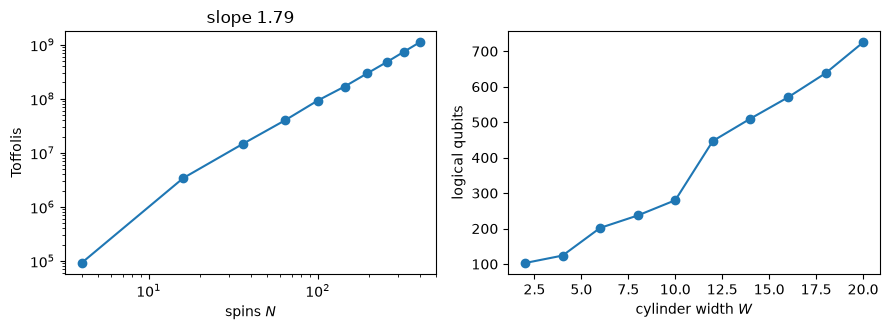

In [6]:
widths = np.arange(2, 21, 2)
costs = [qpe_cost(j1j2_cylinder(W), eps=0.01) for W in widths]
N = widths**2
tof = np.array([c["toffoli"] for c in costs])
slope = np.polyfit(np.log(N[2:]), np.log(tof[2:]), 1)[0]

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].loglog(N, tof, "o-")
ax[0].set(xlabel="spins $N$", ylabel="Toffolis", title=f"slope {slope:.2f}")
ax[1].plot(widths, [c["logical_qubits"] for c in costs], "o-")
ax[1].set(xlabel="cylinder width $W$", ylabel="logical qubits")
fig.tight_layout()

A few hundred logical qubits and $10^7$ to $10^9$ Toffolis: this is the regime of an early fault-tolerant
machine. Note that nothing here grows exponentially. The classical price of notebook 12 does.

## Exercises

1. Make $\epsilon$ ten times smaller. Which factor in the cost formula changes, and by how much?
2. Ask for precision per spin instead, $\epsilon = 10^{-3} N$. How does the Toffoli count now scale with $N$?
3. Set `J2=0` (the unfrustrated square lattice). Why does $\lambda$ barely change, even though the classical
   problem becomes much easier (it has no sign problem for quantum Monte Carlo)?
4. The estimate counts every T gate as a Toffoli. Change that assumption in `qpe_cost` and see how much it matters.